# **MAIN DATASET**

In [ ]:
import zipfile
import os
from collections import defaultdict

def analyze_zip_dataset(zip_path):
    """
    Menghitung jumlah gambar dan anotasi per subset (train/valid/test) dalam file zip.
    Juga mendeteksi kategori N23, N34, N45 berdasarkan nama file.
    """
    stats = defaultdict(lambda: {
        'images': 0,
        'instances': 0,
        'n23': 0, 'n34': 0, 'n45': 0 # Kategori khusus
    })

    if not os.path.exists(zip_path):
        print(f"⚠️ Error: File {zip_path} tidak ditemukan di /content/")
        return None

    try:
        with zipfile.ZipFile(zip_path, 'r') as zf:
            for file_info in zf.infolist():
                if file_info.is_dir():
                    continue

                filename = file_info.filename.lower()
                path_parts = filename.split('/')

                # 1. Menentukan subset (Training, Validation, Test)
                subset = "Unknown"
                for part in path_parts:
                    if 'train' in part:
                        subset = "Training"
                        break
                    elif 'valid' in part or 'val' in part:
                        subset = "Validation"
                        break
                    elif 'test' in part:
                        subset = "Test"
                        break

                if subset == "Unknown":
                    continue

                # 2. Menghitung Gambar
                if filename.endswith(('.jpg', '.jpeg', '.png')):
                    stats[subset]['images'] += 1

                    # Deteksi kategori dari nama file (misal: img_N23_001.jpg)
                    # Sesuaikan kata kunci jika nama file Anda berbeda
                    if 'n23' in filename:
                        stats[subset]['n23'] += 1
                    elif 'n34' in filename:
                        stats[subset]['n34'] += 1
                    elif 'n45' in filename:
                        stats[subset]['n45'] += 1

                # 3. Menghitung Anotasi (Label .txt)
                elif filename.endswith('.txt'):
                    stats[subset]['instances'] += 1

    except zipfile.BadZipFile:
        print(f"⚠️ Error: File {zip_path} rusak atau bukan zip yang valid.")
        return None

    return stats

def print_table():
    # Path langsung ke folder /content/
    FILE_RAW = "/content/Dataset_Raw.zip"
    FILE_AUG = "/content/Dataset_Roboflow.zip"

    print(f"📂 Membaca data dari:\n1. {FILE_RAW}\n2. {FILE_AUG}\n")

    # Analisis kedua file
    raw_stats = analyze_zip_dataset(FILE_RAW)
    aug_stats = analyze_zip_dataset(FILE_AUG)

    if not raw_stats or not aug_stats:
        print("\n❌ Proses dihentikan. Pastikan file ZIP sudah di-upload ke /content/")
        return

    # Header Tabel (Mirip dengan gambar)
    print("=" * 100)
    print(f"{'Subset':<12} | {'Original Images':<15} | {'Images after aug':<15} | {'Original instances (N23/N34/N45)':<30} | {'Instances after aug':<18}")
    print("=" * 100)

    total_raw_img = 0
    total_aug_img = 0
    total_raw_inst = 0
    total_aug_inst = 0

    # Urutan baris agar sesuai gambar
    subsets_order = ["Training", "Validation", "Test"]

    for subset in subsets_order:
        # Ambil data dari dictionary
        raw_img = raw_stats[subset]['images']
        aug_img = aug_stats[subset]['images']

        raw_inst = raw_stats[subset]['instances']
        aug_inst = aug_stats[subset]['instances']

        # Format Original Instances (Total + Rincian N23/N34/N45)
        raw_n23 = raw_stats[subset]['n23']
        raw_n34 = raw_stats[subset]['n34']
        raw_n45 = raw_stats[subset]['n45']

        # Jika tidak ada rincian nama file, kita tampilkan total saja
        if raw_n23 == 0 and raw_n34 == 0 and raw_n45 == 0:
            raw_inst_str = f"{raw_inst}"
        else:
            raw_inst_str = f"{raw_inst} ({raw_n23} / {raw_n34} / {raw_n45})"

        # Akumulasi total
        total_raw_img += raw_img
        total_aug_img += aug_img
        total_raw_inst += raw_inst
        total_aug_inst += aug_inst

        # Print baris
        print(f"{subset:<12} | {raw_img:<15} | {aug_img:<15} | {raw_inst_str:<30} | {aug_inst:<18}")

    print("-" * 100)

    # Akumulasi rincian untuk baris Total
    total_n23 = sum(raw_stats[s]['n23'] for s in subsets_order)
    total_n34 = sum(raw_stats[s]['n34'] for s in subsets_order)
    total_n45 = sum(raw_stats[s]['n45'] for s in subsets_order)

    if total_n23 == 0 and total_n34 == 0 and total_n45 == 0:
        total_raw_inst_str = f"{total_raw_inst}"
    else:
        total_raw_inst_str = f"{total_raw_inst} ({total_n23} / {total_n34} / {total_n45})"

    # Print Total
    print(f"{'Total':<12} | {total_raw_img:<15} | {total_aug_img:<15} | {total_raw_inst_str:<30} | {total_aug_inst:<18}")
    print("=" * 100)

# --- Jalankan Program ---
if __name__ == "__main__":
    print_table()

📂 Membaca data dari:
1. /content/Dataset_Raw.zip
2. /content/Dataset_Roboflow.zip

Subset       | Original Images | Images after aug | Original instances (N23/N34/N45) | Instances after aug
Training     | 470             | 1405            | 470 (220 / 111 / 139)          | 1405              
Validation   | 134             | 134             | 134 (62 / 33 / 39)             | 134               
Test         | 67              | 67              | 67 (23 / 20 / 24)              | 67                
----------------------------------------------------------------------------------------------------
Total        | 671             | 1606            | 671 (305 / 164 / 202)          | 1606              


In [ ]:
import zipfile, os, re
from collections import defaultdict

SUBSETS = {"train": "Training", "valid": "Validation", "val": "Validation", "test": "Test"}
ORDER = ["Training", "Validation", "Test"]

def read_class_names(zf):
    """Ambil urutan kelas dari data.yaml (names: [...] atau names: {0: ..})."""
    for n in zf.namelist():
        if n.lower().endswith("data.yaml"):
            txt = zf.read(n).decode("utf-8", "ignore")
            m = re.search(r"names:\s*\[([^\]]*)\]", txt)
            if m:
                return [s.strip().strip("'\"") for s in m.group(1).split(",")]
            items = re.findall(r"^\s*(\d+)\s*:\s*['\"]?([^'\"\n]+)", txt, re.M)
            if items:
                return [v.strip() for _, v in sorted(items, key=lambda x: int(x[0]))]
    return None

def subset_of(path):
    for part in path.lower().split("/"):
        if part in SUBSETS:
            return SUBSETS[part]
    return None

def analyze(zip_path):
    st = defaultdict(lambda: {"images": 0, "label_files": 0, "instances": 0,
                              "cls": defaultdict(int), "multi": 0, "mismatch": []})
    with zipfile.ZipFile(zip_path) as zf:
        names = read_class_names(zf)
        for info in zf.infolist():
            p = info.filename
            if info.is_dir() or "__MACOSX" in p:
                continue
            sub = subset_of(p)
            if sub is None:
                continue
            low = p.lower()
            if low.endswith((".jpg", ".jpeg", ".png")):
                st[sub]["images"] += 1
            elif low.endswith(".txt") and "/labels/" in low:
                st[sub]["label_files"] += 1
                lines = [l for l in zf.read(info).decode("utf-8", "ignore").splitlines() if l.strip()]
                st[sub]["instances"] += len(lines)
                if len(lines) > 1:
                    st[sub]["multi"] += 1
                cls_in_file = set()
                for l in lines:
                    c = int(float(l.split()[0]))
                    st[sub]["cls"][c] += 1
                    cls_in_file.add(c)
                # cek konsistensi kelas di nama file vs label
                m = re.search(r"n(23|34|45)", os.path.basename(low))
                if m and names:
                    expected = "N" + m.group(1)
                    got = {names[c] for c in cls_in_file if c < len(names)}
                    if got and got != {expected}:
                        st[sub]["mismatch"].append((os.path.basename(p), expected, sorted(got)))
    return st, names

def table(raw_zip, aug_zip):
    raw, names = analyze(raw_zip)
    aug, names_aug = analyze(aug_zip)
    print("Urutan kelas data.yaml (raw):", names, "| (aug):", names_aug)
    idx = {n: i for i, n in enumerate(names)}
    cols = ["N23", "N34", "N45"]
    print("=" * 112)
    print(f"{'Subset':<11}| {'Orig img':<9}| {'Img aug':<8}| {'Orig instances (N23/N34/N45)':<30}"
          f"| {'Inst aug':<9}| {'Img >1 daun':<11}| Mismatch")
    print("=" * 112)
    tot = defaultdict(int); tcls = defaultdict(int)
    for s in ORDER:
        r, a = raw[s], aug[s]
        c = [r["cls"][idx[k]] for k in cols]
        print(f"{s:<11}| {r['images']:<9}| {a['images']:<8}| "
              f"{str(r['instances']) + ' (' + ' / '.join(map(str, c)) + ')':<30}| "
              f"{a['instances']:<9}| {r['multi']:<11}| {len(r['mismatch'])}")
        for k in ["images", "instances", "multi"]:
            tot["r" + k] += r[k]
        tot["aimg"] += a["images"]; tot["ainst"] += a["instances"]
        for k, v in zip(cols, c):
            tcls[k] += v
        if r["images"] != r["label_files"]:
            print(f"   ⚠️ {s}: {r['images']} gambar tetapi {r['label_files']} file label")
    print("-" * 112)
    c = [tcls[k] for k in cols]
    print(f"{'Total':<11}| {tot['rimages']:<9}| {tot['aimg']:<8}| "
          f"{str(tot['rinstances']) + ' (' + ' / '.join(map(str, c)) + ')':<30}| "
          f"{tot['ainst']:<9}| {tot['rmulti']:<11}|")
    print("=" * 112)
    for s in ORDER:
        for f, e, g in raw[s]["mismatch"][:20]:
            print(f"   Mismatch {s}: {f} -> nama file {e}, label {g}")

table("/content/Dataset_Raw.zip", "/content/Dataset_Roboflow.zip")

Urutan kelas data.yaml (raw): ['N23', 'N34', 'N45'] | (aug): ['N23', 'N34', 'N45']
Subset     | Orig img | Img aug | Orig instances (N23/N34/N45)  | Inst aug | Img >1 daun| Mismatch
Training   | 470      | 1405    | 471 (220 / 111 / 140)         | 1408     | 1          | 1
Validation | 134      | 134     | 138 (65 / 34 / 39)            | 138      | 3          | 2
Test       | 67       | 67      | 68 (24 / 20 / 24)             | 68       | 1          | 0
----------------------------------------------------------------------------------------------------------------
Total      | 671      | 1606    | 677 (309 / 165 / 203)         | 1614     | 5          |
   Mismatch Training: N34-98-_JPG.rf.bd5e05feb88bc7140ca164f1b68d6683.txt -> nama file N34, label ['N34', 'N45']
   Mismatch Validation: N23-33-_JPG.rf.3d42331052ecd4633d55befc7d63ed15.txt -> nama file N23, label ['N23', 'N34']
   Mismatch Validation: N34-101-_JPG.rf.1a3bbee0e826cab94d5bb05b52a6c5b1.txt -> nama file N34, label ['N23', 'N

# **DATASET EXTERNAL (NEW DATASET)**

In [2]:
import zipfile
import os
from collections import defaultdict

def analyze_external_test_single_zip(zip_path, cities, class_mapping):
    """
    Count images, annotations, and per-class instances from a SINGLE ZIP file
    that contains one folder per city.
    """
    # Initialize data structure for each city
    stats = {city: {'images': 0, 'label_files': 0, 'instances': 0, 'classes': defaultdict(int)} for city in cities}

    if not os.path.exists(zip_path):
        print(f"⚠️ Error: File {zip_path} not found. Make sure it has been uploaded to /content/")
        return None

    print(f"📂 Reading dataset from: {zip_path}\n")

    try:
        with zipfile.ZipFile(zip_path, 'r') as zf:
            for file_info in zf.infolist():
                if file_info.is_dir():
                    continue

                # Get the full path inside the zip (e.g., "New_Sda/images/img1.jpg")
                filename = file_info.filename
                filename_lower = filename.lower()
                path_parts = filename.split('/')

                # 1. Detect city based on folder name inside the ZIP
                detected_city = None
                for part in path_parts:
                    if part in cities:
                        detected_city = part
                        break

                # Skip files that are not inside the desired city folders
                if not detected_city:
                    continue

                # 2. Count Images
                if filename_lower.endswith(('.jpg', '.jpeg', '.png')):
                    stats[detected_city]['images'] += 1

                # 3. Count Annotation Files (.txt) and Instances (Bounding Boxes)
                elif filename_lower.endswith('.txt'):
                    stats[detected_city]['label_files'] += 1

                    # Read the .txt file to count the number of bounding boxes per class
                    try:
                        with zf.open(file_info) as f:
                            content = f.read().decode('utf-8')
                            lines = content.strip().split('\n')
                            for line in lines:
                                if line.strip() == "":
                                    continue
                                # YOLO format: <class_id> <x_center> <y_center> <width> <height>
                                class_id = int(float(line.split()[0]))
                                stats[detected_city]['instances'] += 1
                                stats[detected_city]['classes'][class_id] += 1
                    except Exception as e:
                        print(f"⚠️ Failed to read label {filename}: {e}")

    except zipfile.BadZipFile:
        print(f"⚠️ Error: File {zip_path} is corrupted or not a valid zip.")
        return None

    return stats

def print_external_test_table(stats, cities, class_mapping):
    if not stats:
        return

    print("=" * 100)
    print("📊 EXTERNAL TEST EVALUATION RESULTS TABLE (New_Data_External.zip)")
    print("=" * 100)

    # Table Header
    header = f"{'City (Location)':<15} | {'Number of Images':<17} | {'Number of Annotations (BBox)':<29} | {'Class Breakdown (N23 / N34 / N45)':<35}"
    print(header)
    print("-" * 100)

    total_images = 0
    total_instances = 0
    total_classes = defaultdict(int)

    for city in cities:
        city_stat = stats[city]
        img_count = city_stat['images']
        inst_count = city_stat['instances']

        # Breakdown per class
        c_dict = city_stat['classes']
        detail_str = []
        for cls_id in sorted(class_mapping.keys()):
            cls_name = class_mapping[cls_id]
            count = c_dict[cls_id]
            detail_str.append(f"{cls_name}: {count}")
            total_classes[cls_id] += count  # Accumulate total

        detail_str_joined = " / ".join(detail_str)

        # Print row
        print(f"{city:<15} | {img_count:<17} | {inst_count:<29} | {detail_str_joined:<35}")

        total_images += img_count
        total_instances += inst_count

    print("-" * 100)

    # Total row
    total_detail_str = []
    for cls_id in sorted(class_mapping.keys()):
        cls_name = class_mapping[cls_id]
        total_detail_str.append(f"{cls_name}: {total_classes[cls_id]}")
    total_detail_joined = " / ".join(total_detail_str)

    print(f"{'TOTAL':<15} | {total_images:<17} | {total_instances:<29} | {total_detail_joined:<35}")
    print("=" * 100)

    print("\n📝 *Note: The 'Number of Annotations' column counts the total bounding boxes inside the .txt files.")


# --- PROGRAM EXECUTION ---

if __name__ == "__main__":
    # 1. Define the path to the external ZIP file in Google Colab / Local
    # File: /content/New_Data_External.zip
    FILE_ZIP = "/content/New_Data_External.zip"

    # 2. Define the city folder names inside the ZIP
    # Make sure these folder names EXACTLY MATCH those inside the ZIP (case-sensitive)
    CITIES = ["New_Sda", "New_Gsk", "New_Kdr"]

    # 3. Define the YOLO Class Mapping
    # Adjust the numbers 0, 1, 2 to match the class_id in your dataset's data.yaml file!
    # If N34 is class 0, change to {0: 'N34', 1: 'N23', 2: 'N45'}
    CLASS_MAPPING = {
        0: 'N23',
        1: 'N34',
        2: 'N45'
    }

    # 4. Run the analysis function
    result_stats = analyze_external_test_single_zip(FILE_ZIP, CITIES, CLASS_MAPPING)

    # 5. Display the table
    if result_stats:
        print_external_test_table(result_stats, CITIES, CLASS_MAPPING)

📂 Reading dataset from: /content/New_Data_External.zip

⚠️ Failed to read label NEW DATA_2/New_Gsk/README.roboflow.txt: could not convert string to float: 'pengujian.gsk'
⚠️ Failed to read label NEW DATA_2/New_Gsk/README.dataset.txt: could not convert string to float: '#'
⚠️ Failed to read label NEW DATA_2/New_Kdr/README.roboflow.txt: could not convert string to float: 'pengujian.kdr'
⚠️ Failed to read label NEW DATA_2/New_Kdr/README.dataset.txt: could not convert string to float: '#'
⚠️ Failed to read label NEW DATA_2/New_Sda/README.roboflow.txt: could not convert string to float: 'pengujian.sda'
⚠️ Failed to read label NEW DATA_2/New_Sda/README.dataset.txt: could not convert string to float: '#'
📊 EXTERNAL TEST EVALUATION RESULTS TABLE (New_Data_External.zip)
City (Location) | Number of Images  | Number of Annotations (BBox)  | Class Breakdown (N23 / N34 / N45)  
----------------------------------------------------------------------------------------------------
New_Sda         | 37 

In [4]:
# -*- coding: utf-8 -*-
"""
Check EXTERNAL TEST SET similarity against the MAIN DATASET (train/valid/test)
  1) MD5 hashing      -> byte-per-byte identical files
  2) pHash (8 orientations: 0/90/180/270 rotations + flips) -> nearly identical even if resized/re-encoded/rotated
  3) Feature matching (ORB + ratio test + RANSAC)   -> same leaves/scenes even if angle, scale, or crop differs
  4) Candidate pairs for visual inspection
"""
!pip install imagehash
import io, os, zipfile, hashlib, shutil
from collections import defaultdict
import cv2
import numpy as np
import pandas as pd
import imagehash
from PIL import Image, ImageOps

# =========================== CONFIGURATION ===========================
EXTERNAL_ZIP = "/content/New_Data_External.zip"  # external zip (one folder per city)
CITIES       = ["New_Sda", "New_Gsk", "New_Kdr"]
MAIN_ZIP     = "/content/Dataset_Raw.zip"        # main dataset WITHOUT augmentation (671 images)
MAIN_SPLITS  = {"train": "train", "valid": "valid", "val": "valid", "test": "test"}
OUT_DIR      = "/content/similarity_check"       # Results stored locally in Colab, NOT in Drive

PHASH_THR        = 10     # pHash Hamming distance (64-bit) <= this -> near-duplicate candidate
USE_LEAF_MASK    = True   # ORB only on leaf area (label polygons) -> ignore LCC chart
MASK_DILATE_FRAC = 0.03   # mask dilation = 3% of longest side
ORB_FEATURES     = 2000
MAX_SIDE         = 1024
RATIO            = 0.75   # Lowe ratio test
MIN_GOOD         = 15
FLAG_INLIERS     = 40     # flagged if RANSAC inliers >= this ...
FLAG_INL_RATIO   = 0.30   # ... AND inliers/good matches >= this
N_INSPECT_TOP    = 20     # save top N highest inlier pairs for visual check
# =====================================================================
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")

def label_path_for(img_path, names):
    stem, _ = os.path.splitext(img_path)
    cand = stem.replace("/images/", "/labels/") + ".txt"
    if cand in names:
        return cand
    return stem + ".txt" if stem + ".txt" in names else None

def read_polygons(txt):
    polys = []
    for line in txt.strip().splitlines():
        v = line.split()
        if len(v) < 5:
            continue
        xy = np.array(list(map(float, v[1:])), dtype=np.float32)
        if len(xy) == 4:  # bbox -> rectangle
            cx, cy, w, h = xy
            xy = np.array([cx-w/2, cy-h/2, cx+w/2, cy-h/2, cx+w/2, cy+h/2, cx-w/2, cy+h/2], dtype=np.float32)
        polys.append(xy.reshape(-1, 2))
    return polys

def load_zip(zip_path, set_name, group_of):
    if not os.path.exists(zip_path):
        raise FileNotFoundError(zip_path)
    recs = []
    with zipfile.ZipFile(zip_path) as zf:
        names = set(zf.namelist())
        for info in zf.infolist():
            p = info.filename
            if info.is_dir() or not p.lower().endswith(IMG_EXT) or "__MACOSX" in p:
                continue
            group = group_of(p)
            if group is None:
                continue
            lp = label_path_for(p, names)
            polys = read_polygons(zf.read(lp).decode("utf-8", "ignore")) if lp else []
            recs.append(dict(set=set_name, group=group, path=p, file=os.path.basename(p),
                             data=zf.read(info), polys=polys, has_label=lp is not None))
    return recs

def city_of(p):
    return next((part for part in p.split("/") if part in CITIES), None)

def split_of(p):
    return next((MAIN_SPLITS[x.lower()] for x in p.split("/") if x.lower() in MAIN_SPLITS), "unknown")

def pil_open(data):
    return ImageOps.exif_transpose(Image.open(io.BytesIO(data))).convert("RGB")

def dihedral(img):
    out = []
    for k in range(4):
        r = img.rotate(90 * k, expand=True)
        out += [r, ImageOps.mirror(r)]
    return out

def orb_features(rec, orb):
    img = cv2.imdecode(np.frombuffer(rec["data"], np.uint8), cv2.IMREAD_GRAYSCALE)
    h, w = img.shape
    s = MAX_SIDE / max(h, w)
    if s < 1:
        img = cv2.resize(img, (int(w*s), int(h*s)), interpolation=cv2.INTER_AREA)
        h, w = img.shape
    mask = None
    if USE_LEAF_MASK and rec["polys"]:
        mask = np.zeros((h, w), np.uint8)
        for poly in rec["polys"]:
            cv2.fillPoly(mask, [np.round(poly * [w, h]).astype(np.int32)], 255)
        k = max(3, int(MASK_DILATE_FRAC * max(h, w)) | 1)
        mask = cv2.dilate(mask, np.ones((k, k), np.uint8))
    kp, des = orb.detectAndCompute(img, mask)
    return img, kp, des

def match_pair(f1, f2, bf):
    _, kp1, d1 = f1
    _, kp2, d2 = f2
    if d1 is None or d2 is None or len(kp1) < 2 or len(kp2) < 2:
        return 0, 0, None, None
    good = [m for m, n in (x for x in bf.knnMatch(d1, d2, k=2) if len(x) == 2)
            if m.distance < RATIO * n.distance]
    if len(good) < MIN_GOOD:
        return len(good), 0, good, None
    src = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    _, inl = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
    return len(good), int(inl.sum()) if inl is not None else 0, good, inl

def save_inspection(fe, fm, good, inl, info, path):
    img1, kp1, _ = fe
    img2, kp2, _ = fm
    keep = [g for g, i in zip(good, inl.ravel()) if i] if inl is not None else []
    vis = cv2.drawMatches(img1, kp1, img2, kp2, keep[:200], None, matchColor=(0, 255, 0),
                          flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    cv2.putText(vis, info, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)
    cv2.imwrite(path, vis)

def main():
    os.makedirs(OUT_DIR, exist_ok=True)
    insp_dir = os.path.join(OUT_DIR, "inspect")
    shutil.rmtree(insp_dir, ignore_errors=True)
    os.makedirs(insp_dir)

    print("📂 Reading zip files ...")
    ext = load_zip(EXTERNAL_ZIP, "external", city_of)
    main_ = load_zip(MAIN_ZIP, "main", split_of)
    print(f"   external: {len(ext)} images | main: {len(main_)} images")
    print("   main per split:", pd.Series([r['group'] for r in main_]).value_counts().to_dict())
    if len(main_) > 700:
        print("⚠️  Main > 700 images: ensure you are using the export WITHOUT augmentation (671 images).")
    no_lab = sum(not r["has_label"] for r in ext + main_)
    if USE_LEAF_MASK and no_lab:
        print(f"⚠️  {no_lab} images without labels -> ORB uses the whole image.")

    # ---------- 1) MD5 ----------
    print("\n🔑 1) MD5 hashing ...")
    for r in ext + main_:
        r["md5"] = hashlib.md5(r["data"]).hexdigest()
    md5_main = defaultdict(list)
    for r in main_:
        md5_main[r["md5"]].append(r)
    md5_rows = [dict(ext_group=e["group"], ext_file=e["file"], main_split=m["group"], main_file=m["file"], md5=e["md5"])
                for e in ext for m in md5_main.get(e["md5"], [])]
    md5_ext = defaultdict(list)
    for e in ext:
        md5_ext[e["md5"]].append(e)
    md5_within = [dict(md5=k, n=len(v), files="; ".join(f"{x['group']}/{x['file']}" for x in v))
                  for k, v in md5_ext.items() if len(v) > 1]
    pd.DataFrame(md5_rows).to_csv(os.path.join(OUT_DIR, "1_md5_external_vs_main.csv"), index=False)
    pd.DataFrame(md5_within).to_csv(os.path.join(OUT_DIR, "1_md5_within_external.csv"), index=False)
    print(f"   identical external-main: {len(md5_rows)} | identical within external: {len(md5_within)} groups")

    # ---------- 2) pHash ----------
    print("\n🖼️  2) pHash (8 orientations) ...")
    for r in main_:
        r["ph"] = imagehash.phash(pil_open(r["data"]))
    for e in ext:
        e["ph8"] = [imagehash.phash(v) for v in dihedral(pil_open(e["data"]))]
    D = np.array([[min(h - m["ph"] for h in e["ph8"]) for m in main_] for e in ext], dtype=int)
    ph_rows = []
    for i, e in enumerate(ext):
        j = int(D[i].argmin())
        ph_rows.append(dict(ext_group=e["group"], ext_file=e["file"], nearest_main_split=main_[j]["group"],
                            nearest_main_file=main_[j]["file"], min_phash_dist=int(D[i, j]),
                            n_main_le_thr=int((D[i] <= PHASH_THR).sum())))
    ph_df = pd.DataFrame(ph_rows).sort_values("min_phash_dist")
    ph_df.to_csv(os.path.join(OUT_DIR, "2_phash_nearest_main.csv"), index=False)
    pairs = [dict(ext_group=ext[i]["group"], ext_file=ext[i]["file"], main_split=main_[j]["group"],
                  main_file=main_[j]["file"], phash_dist=int(D[i, j])) for i, j in zip(*np.where(D <= PHASH_THR))]
    pd.DataFrame(pairs).to_csv(os.path.join(OUT_DIR, "2_phash_pairs_le_thr.csv"), index=False)
    within = []
    for a in range(len(ext)):
        for b in range(a + 1, len(ext)):
            d = min(h - ext[b]["ph8"][0] for h in ext[a]["ph8"])
            if d <= PHASH_THR:
                within.append(dict(file_a=f"{ext[a]['group']}/{ext[a]['file']}",
                                   file_b=f"{ext[b]['group']}/{ext[b]['file']}", phash_dist=d))
    pd.DataFrame(within).to_csv(os.path.join(OUT_DIR, "2_phash_within_external.csv"), index=False)
    print(f"   external-main pairs dist <= {PHASH_THR}: {len(pairs)} | min dist: {D.min()} | "
          f"median nearest dist: {np.median(D.min(1)):.0f}")
    print(f"   similar pairs within external: {len(within)}")

    # ---------- 3) Feature matching ----------
    print(f"\n🧩 3) ORB all pairs {len(ext)} x {len(main_)} (leaf mask={USE_LEAF_MASK}) ...")
    orb = cv2.ORB_create(nfeatures=ORB_FEATURES)
    bf = cv2.BFMatcher(cv2.NORM_HAMMING)
    fm = [orb_features(r, orb) for r in main_]
    fm_rows = []
    for i, e in enumerate(ext):
        fe = orb_features(e, orb)
        for j, m in enumerate(main_):
            n_good, n_inl, _, _ = match_pair(fe, fm[j], bf)
            ratio = n_inl / n_good if n_good else 0.0
            fm_rows.append(dict(ext_group=e["group"], ext_file=e["file"], main_split=m["group"], main_file=m["file"],
                                good_matches=n_good, ransac_inliers=n_inl, inlier_ratio=round(ratio, 3),
                                phash_dist=int(D[i, j]),
                                flagged=(n_inl >= FLAG_INLIERS and ratio >= FLAG_INL_RATIO), i=i, j=j))
        if (i + 1) % 10 == 0 or i + 1 == len(ext):
            print(f"   {i + 1}/{len(ext)} external images completed")
    fm_df = pd.DataFrame(fm_rows).sort_values("ransac_inliers", ascending=False)
    best = fm_df.drop_duplicates(["ext_group", "ext_file"])
    best.drop(columns=["i", "j"]).to_csv(os.path.join(OUT_DIR, "3_feature_best_per_external.csv"), index=False)
    flagged = fm_df[fm_df.flagged]
    flagged.drop(columns=["i", "j"]).to_csv(os.path.join(OUT_DIR, "3_feature_flagged_pairs.csv"), index=False)

    # ---------- 4) Visual inspection ----------
    insp = pd.concat([flagged, fm_df.head(N_INSPECT_TOP), fm_df[fm_df.phash_dist <= PHASH_THR]]).drop_duplicates(["i", "j"])
    for k, row in enumerate(insp.itertuples()):
        e, m = ext[row.i], main_[row.j]
        fe = orb_features(e, orb)
        _, _, good, inl = match_pair(fe, fm[row.j], bf)
        info = f"inl={row.ransac_inliers} good={row.good_matches} pHash={row.phash_dist}"
        name = (f"{k:03d}_{e['group']}_{os.path.splitext(e['file'])[0][:40]}__"
                f"{m['group']}_{os.path.splitext(m['file'])[0][:40]}.jpg")
        save_inspection(fe, fm[row.j], good or [], inl, info, os.path.join(insp_dir, name))
    shutil.make_archive(os.path.join(OUT_DIR, "inspect"), "zip", insp_dir)

    # ---------- Summary ----------
    summ = []
    for c in CITIES:
        n_img = sum(e["group"] == c for e in ext)
        b = best[best.ext_group == c]
        summ.append(dict(site=c, images=n_img,
                         md5_identical=sum(r["ext_group"] == c for r in md5_rows),
                         phash_le_thr=int(((ph_df.ext_group == c) & (ph_df.min_phash_dist <= PHASH_THR)).sum()),
                         min_phash_dist=int(ph_df[ph_df.ext_group == c].min_phash_dist.min()) if n_img else None,
                         feature_flagged=int(flagged[flagged.ext_group == c].ext_file.nunique()),
                         max_inliers=int(b.ransac_inliers.max()) if len(b) else None))
    summ_df = pd.DataFrame(summ)
    summ_df.to_csv(os.path.join(OUT_DIR, "0_summary.csv"), index=False)

    print("\n" + "=" * 100)
    print("📊 SUMMARY (number of EXTERNAL images per criterion)")
    print("=" * 100)
    print(summ_df.to_string(index=False))
    print("=" * 100)
    print(f"Criteria: MD5 identical | pHash <= {PHASH_THR} (8 orientations) | ORB inliers >= {FLAG_INLIERS} & ratio >= {FLAG_INL_RATIO}")
    print(f"📁 Output: {OUT_DIR}  (0_summary.csv, 1_md5_*.csv, 2_phash_*.csv, 3_feature_*.csv, inspect.zip)")
    print("👉 Flagged pairs are NOT automatically duplicates: open inspect.zip and decide visually.")

if __name__ == "__main__":
    main()

📂 Reading zip files ...
   external: 130 images | main: 671 images
   main per split: {'train': 470, 'valid': 134, 'test': 67}

🔑 1) MD5 hashing ...
   identical external-main: 0 | identical within external: 0 groups

🖼️  2) pHash (8 orientations) ...
   external-main pairs dist <= 10: 1 | min dist: 10 | median nearest dist: 16
   similar pairs within external: 0

🧩 3) ORB all pairs 130 x 671 (leaf mask=True) ...
   10/130 external images completed
   20/130 external images completed
   30/130 external images completed
   40/130 external images completed
   50/130 external images completed
   60/130 external images completed
   70/130 external images completed
   80/130 external images completed
   90/130 external images completed
   100/130 external images completed
   110/130 external images completed
   120/130 external images completed
   130/130 external images completed

📊 SUMMARY (number of EXTERNAL images per criterion)
   site  images  md5_identical  phash_le_thr  min_phash_di

In [6]:
import pandas as pd
OUT = "/content/similarity_check"
f = pd.read_csv(f"{OUT}/3_feature_flagged_pairs.csv")

print(f.groupby("ext_group").ransac_inliers.describe().round(1))

# Negative control: Sidoarjo is not present in the main dataset
neg_max = f.loc[f.ext_group == "New_Sda", "ransac_inliers"].max()
print(f"\nMaximum inliers at the site NOT present in the main dataset (Sidoarjo): {neg_max}")

cand = (f[f.ransac_inliers > neg_max]
        .sort_values("ransac_inliers", ascending=False)
        .drop_duplicates(["ext_group", "ext_file"]))
print(f"\nExternal images with inliers > {neg_max}: {len(cand)}")
print(cand[["ext_group", "ext_file", "main_split", "main_file",
            "ransac_inliers", "inlier_ratio", "phash_dist"]].to_string(index=False))

# File for recording visual inspection results
cand["decision"] = ""   # fill in: same_photo / same_leaf_diff_session / different
cand.to_csv(f"{OUT}/4_visual_review.csv", index=False)

           count  mean   std   min   25%   50%   75%    max
ext_group                                                  
New_Gsk    161.0  56.0  17.1  40.0  45.0  50.0  62.0  134.0
New_Kdr    122.0  57.6  21.1  40.0  44.0  50.0  60.8  163.0
New_Sda      5.0  48.2   5.7  43.0  43.0  47.0  52.0   56.0

Maximum inliers at the site NOT present in the main dataset (Sidoarjo): 56

External images with inliers > 56: 24
ext_group                                                ext_file main_split                                            main_file  ransac_inliers  inlier_ratio  phash_dist
  New_Kdr  KDR_S1_003_jpg.rf.c20a2e66834624fffd2810a4444cfbc8.jpg      train N45-109-_jpg.rf.75e0c35c4743d96796dc60dc4b3c4e50.jpg             163         0.964          20
  New_Gsk  GSK_S1_013_jpg.rf.a585f12026cb5ec5e3fb22e04df82a09.jpg      valid N45-120-_jpg.rf.dc2502346b226da848dabd8a2ad16ae2.jpg             134         0.744          24
  New_Kdr  KDR_S1_004_jpg.rf.a5a62ac5467c4117aaf0c59eb6203a1f.jpg    

# **PRE-PROCESSING**

PREPROCESSING PIPELINE (BO-SELECTED PARAMETERS, TABLE 5)
  gamma_min             : 0.7825
  gamma_max             : 1.2026
  gamma_target_mean     : 0.4835
  edge_blur_sigma       : 0.6074
  edge_strength         : 0.0469
  hsv_saturation_gain   : 1.0171
Pipeline: Gamma -> Edge -> HSV; labels copied unchanged

Extracting /content/Dataset_Roboflow.zip ...
✓ Extraction complete -> /content/Dataset_Raw

================= DATASET CHECK REPORT =================


--- TRAIN ---
Total images      : 1405
Corrupt images    : 0
Valid object      : 1405
Valid background  : 0
Missing label     : 0
Invalid label     : 0
Orphan label      : 0
Class distribution: {'N23': 658, 'N34': 333, 'N45': 417}
Resolution (WxH) min 211x121  max 2048x2048

--- VALID ---
Total images      : 134
Corrupt images    : 0
Valid object      : 134
Valid background  : 0
Missing label     : 0
Invalid label     : 0
Orphan label      : 0
Class distribution: {'N23': 65, 'N34': 34, 'N45': 39}
Resolution (WxH) min 234x160  max 2

Validation: 100%|██████████| 50/50 [00:13<00:00,  3.60it/s]



1. MEAN INTENSITY (grayscale, 0-255)
RAW         : mean= 106.1  std=  37.1
Gamma       : mean= 115.7  std=  30.1
Edge        : mean= 115.7  std=  30.1
HSV (final) : mean= 115.4  std=  30.2

2. SATURATION MEAN (HSV S, 0-255)
RAW         :  104.8
Gamma       :   95.3
Edge        :   95.3
HSV (final) :   97.4

3. CONTRAST (std grayscale)
RAW         :   48.1
Gamma       :   50.2
Edge        :   50.2
HSV (final) :   50.2

4. SATURATION EXTREMES (% pixels): S=255 / S=0
RAW         : 2.5233% / 8.0590%
Gamma       : 2.5093% / 8.0762%
Edge        : 2.5071% / 8.0791%
HSV (final) : 2.5661% / 8.0791%

5. EFFECTIVE GAMMA
mean=0.876 std=0.140 min=0.782 max=1.203
Clip range [0.7825, 1.2026]; clipped: 66.0%

6. Δ MEAN INTENSITY PER STAGE
RAW→Gamma   +9.6 | Gamma→Edge   +0.0 | Edge→HSV   -0.3 | RAW→FINAL   +9.3

7. FOREGROUND-BACKGROUND SEPARATION (Hellinger, 50 images)
Channel       RAW    FINAL        Δ
H          0.5901   0.5870  -0.0031
S          0.7018   0.7034  +0.0016
V          0.7667   0.76

Stage separation: 100%|██████████| 30/30 [00:12<00:00,  2.40it/s]



AVERAGE HELLINGER DISTANCE (foreground vs background) PER STAGE
Stage                              H       S       V       L       a       b      AVG
raw                           0.5886  0.6992  0.7934  0.7824  0.6470  0.6139   0.6874
+gamma                        0.5884  0.6989  0.7939  0.7818  0.6200  0.5767   0.6766
+gamma+edge                   0.5884  0.6988  0.7938  0.7818  0.6200  0.5767   0.6766
+gamma+edge+hsv (full)        0.5797  0.7006  0.7938  0.7815  0.6203  0.5840   0.6766
Note: pixel-level measure, NOT evidence of mAP improvement.


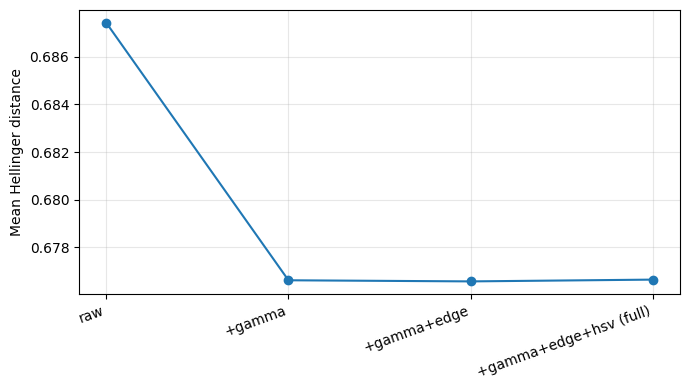


DATASET VALIDATION BEFORE PREPROCESSING

================= DATASET CHECK REPORT =================


--- TRAIN ---
Total images      : 1405
Corrupt images    : 0
Valid object      : 1405
Valid background  : 0
Missing label     : 0
Invalid label     : 0
Orphan label      : 0
Class distribution: {'N23': 658, 'N34': 333, 'N45': 417}
Resolution (WxH) min 211x121  max 2048x2048

--- VALID ---
Total images      : 134
Corrupt images    : 0
Valid object      : 134
Valid background  : 0
Missing label     : 0
Invalid label     : 0
Orphan label      : 0
Class distribution: {'N23': 65, 'N34': 34, 'N45': 39}
Resolution (WxH) min 234x160  max 2048x2048

--- TEST ---
Total images      : 67
Corrupt images    : 0
Valid object      : 67
Valid background  : 0
Missing label     : 0
Invalid label     : 0
Orphan label      : 0
Class distribution: {'N23': 24, 'N34': 20, 'N45': 24}
Resolution (WxH) min 210x139  max 2048x2048



Processing train...


100%|██████████| 1405/1405 [00:55<00:00, 25.52it/s]



Processing valid...


100%|██████████| 134/134 [00:05<00:00, 24.33it/s]



Processing test...


100%|██████████| 67/67 [00:01<00:00, 33.80it/s]


[SUCCESS] data.yaml created: /content/Dataset_Gamma/data.yaml

PROCESSED DATASET VALIDATION (structural integrity)
[OK] Images train: 1405 images matched
[OK] Labels train: 1405 labels matched
[OK] Label content train: all identical
[OK] Resolution train: all consistent
[OK] Images valid: 134 images matched
[OK] Labels valid: 134 labels matched
[OK] Label content valid: all identical
[OK] Resolution valid: all consistent
[OK] Images test: 67 images matched
[OK] Labels test: 67 labels matched
[OK] Label content test: all identical
[OK] Resolution test: all consistent
✅ OUTPUT VALIDATION: ALL PASSED


PROCESSED DATASET COMPLETE
Total processed : 1606 (object 1606, background 0); failed 0
Pipeline (BO-selected parameters, Table 5):
  1. Adaptive gamma : bounds [0.7825, 1.2026], target mean 0.4835
  2. Edge enhance   : sigma 0.6074, strength 0.0469
  3. HSV saturation : gain 1.0171
Total time 76.02 s; average 38.66 ms/image
RAW size 101.99 MB; PROCESSED 204.65 MB

Dataset zipped -> /conten

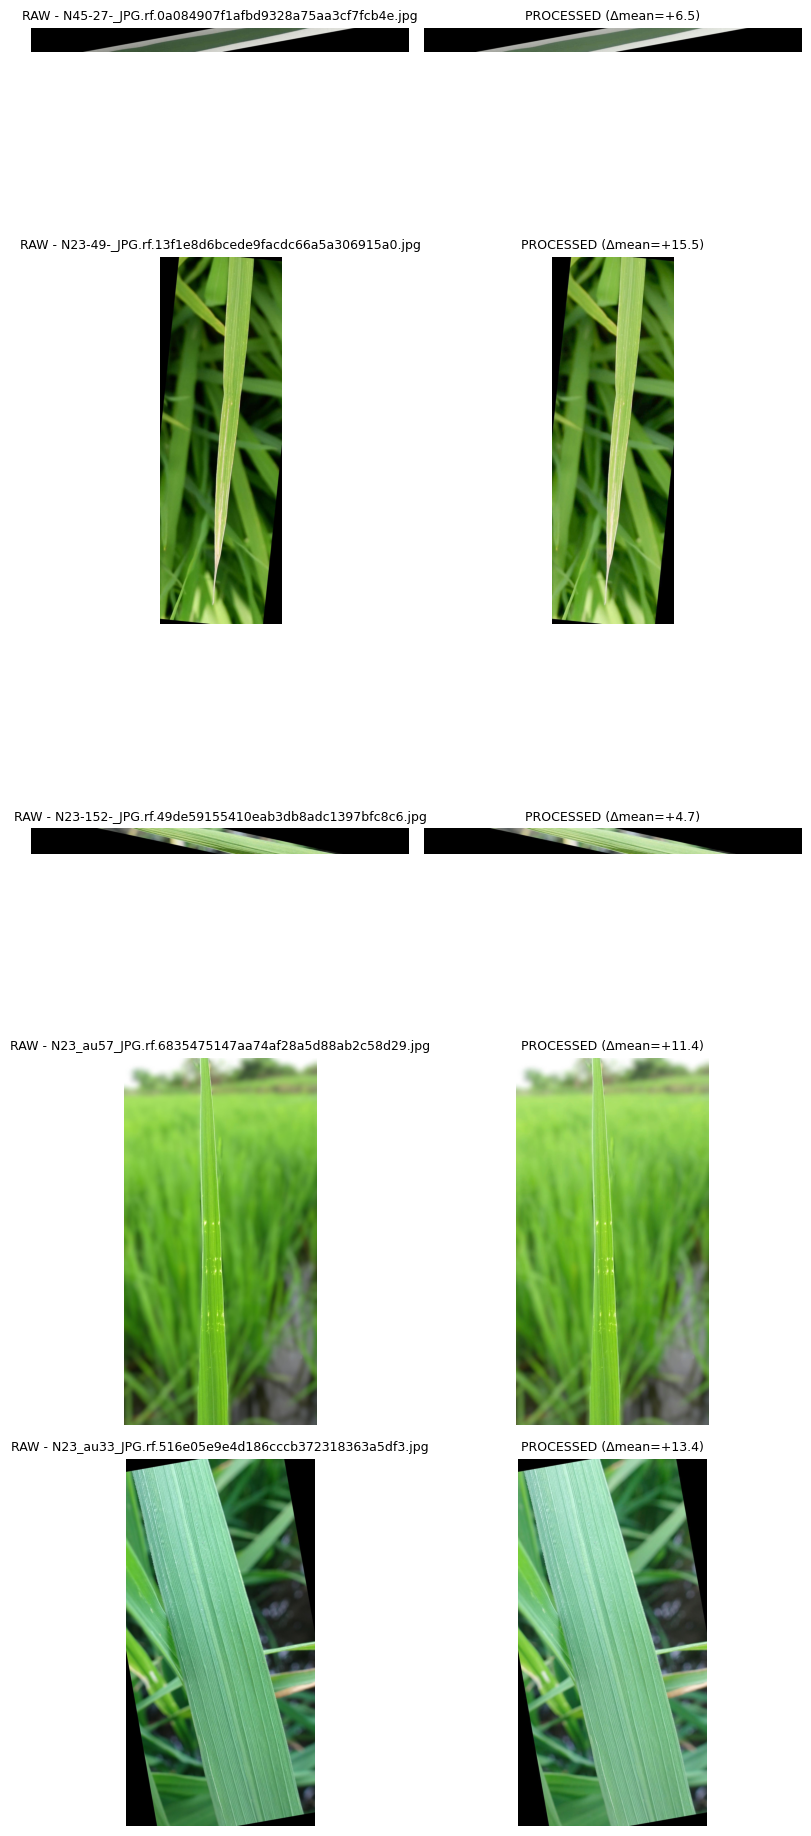


Note: the effect of preprocessing on model performance is tested separately through an ablation study
(Raw vs Processed, single-stage vs sequential fine-tuning, 3 seeds) on the validation subset.



In [9]:
# ============================================================
# build_processed_dataset.py
#
# Builds the PROCESSED dataset (Dataset_Gamma_New) from the RAW Roboflow export using the
# colour-preserving pipeline with the parameters SELECTED BY BAYESIAN OPTIMIZATION (Table 5):
#
#   Adaptive gamma  -> Edge enhancement (unsharp masking) -> HSV saturation gain
#
#   gamma      = clip( ln(T) / ln(mu), gamma_min, gamma_max ),  mu = mean intensity of the image (0-1)
#   I_gamma    = I ** gamma
#   I_edge     = (1 + alpha) * I_gamma - alpha * G_sigma(I_gamma)
#   S_out      = clip(g_s * S, 0, 255)  (HSV), H and V unchanged
#
# Label files are copied unchanged. The script also checks dataset integrity, reports
# pixel-level diagnostics, and previews raw vs processed images.
# Run on Google Colab.
# ============================================================

import os
import cv2
import time
import random
import zipfile
import shutil
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from enum import Enum


# ============================================================
# PATH CONFIG
# ============================================================

ZIP_PATH = "/content/Dataset_Roboflow.zip"
INPUT_ROOT = "/content/Dataset_Raw"
OUTPUT_ROOT = "/content/Dataset_Gamma"
OUTPUT_ZIP_PATH = "/content/Dataset_Gamma_New.zip"
SPLITS = ["train", "valid", "test"]
IMG_EXTS = (".jpg", ".jpeg", ".png")

# ============================================================
# CLASS MAPPING
# ============================================================
# 0: N23 (LCC 2.0-2.5)   1: N34 (LCC 3.0-3.5)   2: N45 (LCC 4.0-5.0)

EXPECTED_CLASSES = [0, 1, 2]
CLASS_NAMES = {0: "N23", 1: "N34", 2: "N45"}


# ============================================================
# RUN CONTROL
# ============================================================

RUN_EXTRACT = True
RUN_CHECK_RAW = True
RUN_PREPROCESSING = True
AUTO_ZIP_OUTPUT = True
RUN_PREVIEW_BEFORE_AFTER = True
PREVIEW_N_SAMPLES = 5

RUN_NUMERICAL_VALIDATION = True
NUM_VALIDATION_SAMPLES = 50

RUN_ABLATION_STUDY = True          # pixel-level fg/bg separation per stage (diagnostic only)
ABLATION_SPLIT = "train"
ABLATION_N_SAMPLES = 30
ABLATION_SHOW_PLOT = True

RUN_MODEL_PERFORMANCE_NOTE = True

CLEAR_OUTPUT_BEFORE_PROCESS = True
EXTRACT_OVERWRITE = True


# ============================================================
# PREPROCESSING CONFIG = PARAMETERS SELECTED BY BAYESIAN OPTIMIZATION (Table 5)
# ============================================================
#
# | Stage                 | Parameter                 | Selected value |
# |-----------------------|---------------------------|----------------|
# | Adaptive gamma        | Lower gamma bound         | 0.7825         |
# |                       | Upper gamma bound         | 1.2026         |
# |                       | Target mean intensity     | 0.4835         |
# | Edge enhancement      | Gaussian blur sigma       | 0.6074         |
# |                       | Edge strength (alpha)     | 0.0469         |
# | HSV enhancement       | Saturation gain           | 1.0171         |
# ============================================================

CONFIG = {
    # Adaptive gamma correction
    "gamma_min": 0.7825,
    "gamma_max": 1.2026,
    "gamma_target_mean": 0.4835,
    "gamma_epsilon": 1e-6,

    # Edge enhancement (unsharp masking):  I_edge = (1+alpha)*I - alpha*G_sigma(I)
    "edge_blur_sigma": 0.6074,
    "edge_strength": 0.0469,

    # HSV saturation adjustment
    "hsv_saturation_gain": 1.0171,
}


# ============================================================
# ENUM FOR LABEL STATUS
# ============================================================

class LabelStatus(Enum):
    VALID_OBJECT = "valid_object"
    VALID_BACKGROUND = "valid_background"
    MISSING_LABEL = "missing_label"
    INVALID_LABEL = "invalid_label"


# ============================================================
# PART 1: ZIP EXTRACTION
# ============================================================

def extract_dataset_zip(zip_path=ZIP_PATH, extract_to=INPUT_ROOT, overwrite=EXTRACT_OVERWRITE):
    """Extract dataset from ZIP file with path traversal safety"""
    if not os.path.exists(zip_path):
        raise FileNotFoundError(f"Zip not found: {zip_path}")

    if os.path.exists(extract_to):
        if overwrite:
            print(f"\nDeleting old folder: {extract_to}")
            shutil.rmtree(extract_to)
        else:
            print(f"[SKIP] {extract_to} already exists. Set overwrite=True to re-extract.")
            return extract_to

    tmp_extract = extract_to + "_tmp_extract"
    if os.path.exists(tmp_extract):
        shutil.rmtree(tmp_extract)

    print(f"\nExtracting {zip_path} ...")
    with zipfile.ZipFile(zip_path, "r") as zf:
        bad_file = zf.testzip()
        if bad_file:
            raise RuntimeError(f"Corrupt zip, problematic file: {bad_file}")
        for member in zf.namelist():
            normalized = os.path.normpath(member)
            if normalized.startswith(('..', '/')) or normalized == '.':
                raise RuntimeError(f"Zip contains unsafe path: {member}")
        zf.extractall(tmp_extract)

    top_items = [i for i in os.listdir(tmp_extract) if not i.startswith("__MACOSX")]
    if any(s in top_items for s in SPLITS):
        os.rename(tmp_extract, extract_to)
    else:
        found = False
        for item in top_items:
            candidate = os.path.join(tmp_extract, item)
            if os.path.isdir(candidate) and any(s in os.listdir(candidate) for s in SPLITS):
                shutil.move(candidate, extract_to)
                found = True
                break
        shutil.rmtree(tmp_extract, ignore_errors=True)
        if not found:
            raise RuntimeError("Unrecognized zip structure. Make sure the zip contains train/valid/test folders.")

    print(f"✓ Extraction complete -> {extract_to}")
    return extract_to


# ============================================================
# PART 2: LABEL VALIDATION
# ============================================================

def calculate_polygon_area(points):
    """Calculate polygon area using the shoelace formula"""
    if len(points) < 3:
        return 0.0
    x, y = points[:, 0], points[:, 1]
    return 0.5 * np.abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1)))


def validate_yolo_segmentation_label(lbl_path, expected_classes=None):
    """Validate YOLO segmentation label. Returns (LabelStatus, dict)."""
    if expected_classes is None:
        expected_classes = EXPECTED_CLASSES
    if not os.path.exists(lbl_path):
        return LabelStatus.MISSING_LABEL, {"error": "File not found"}
    if os.path.getsize(lbl_path) == 0:
        return LabelStatus.VALID_BACKGROUND, {"is_background": True}
    try:
        with open(lbl_path, "r") as f:
            lines = f.readlines()
    except Exception as e:
        return LabelStatus.INVALID_LABEL, {"error": f"Cannot read file: {e}"}
    if len(lines) == 0:
        return LabelStatus.VALID_BACKGROUND, {"is_background": True}

    class_ids, polygon_counts, polygon_areas, errors = [], [], [], []
    for line_no, line in enumerate(lines, start=1):
        line = line.strip()
        if not line:
            continue
        parts = line.split()
        if len(parts) < 7:
            errors.append(f"Line {line_no}: Fewer than 7 tokens ({len(parts)} tokens)")
            continue
        try:
            class_id = int(parts[0])
        except ValueError:
            errors.append(f"Line {line_no}: Class ID is not an integer: '{parts[0]}'")
            continue
        if expected_classes and class_id not in expected_classes:
            errors.append(f"Line {line_no}: Unknown Class ID {class_id} (expected: {expected_classes})")
            continue
        try:
            coords = list(map(float, parts[1:]))
        except ValueError as e:
            errors.append(f"Line {line_no}: Coordinates are not numbers: {e}")
            continue
        if len(coords) % 2 != 0:
            errors.append(f"Line {line_no}: Odd number of coordinates ({len(coords)})")
            continue
        if len(coords) < 6:
            errors.append(f"Line {line_no}: At least 3 points required for polygon ({len(coords)//2} points)")
            continue
        if any(c < 0.0 or c > 1.0 for c in coords):
            errors.append(f"Line {line_no}: Coordinates out of range 0-1")
            continue
        points = np.array([[coords[i], coords[i + 1]] for i in range(0, len(coords), 2)])
        area = calculate_polygon_area(points)
        if area < 0.001:
            errors.append(f"Line {line_no}: Degenerate polygon (area={area:.6f})")
            continue
        class_ids.append(class_id)
        polygon_counts.append(len(coords) // 2)
        polygon_areas.append(area)

    if errors:
        return LabelStatus.INVALID_LABEL, {"errors": errors, "class_ids": class_ids,
                                           "polygon_counts": polygon_counts, "polygon_areas": polygon_areas}
    if class_ids:
        return LabelStatus.VALID_OBJECT, {"class_ids": class_ids, "polygon_counts": polygon_counts,
                                          "polygon_areas": polygon_areas, "total_polygons": len(class_ids)}
    return LabelStatus.VALID_BACKGROUND, {"is_background": True}


def classify_label(lbl_path, expected_classes=None):
    return validate_yolo_segmentation_label(lbl_path, expected_classes or EXPECTED_CLASSES)


def polygon_mask_from_label(lbl_path, img_shape):
    """Rasterise all YOLO-seg polygons of a label file into a binary mask (1 = leaf)."""
    h, w = img_shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)
    if not os.path.exists(lbl_path) or os.path.getsize(lbl_path) == 0:
        return mask
    try:
        with open(lbl_path, "r") as f:
            lines = f.readlines()
    except Exception:
        return mask
    for line in lines:
        parts = line.strip().split()
        if len(parts) < 7:
            continue
        try:
            coords = list(map(float, parts[1:]))
        except ValueError:
            continue
        if len(coords) % 2 != 0 or len(coords) < 6:
            continue
        coords = np.clip(coords, 0.0, 1.0)
        pts = np.array([[coords[i] * w, coords[i + 1] * h] for i in range(0, len(coords), 2)], dtype=np.int32)
        cv2.fillPoly(mask, [pts], 1)
    return mask


# ============================================================
# PART 3: DATASET INTEGRITY CHECK
# ============================================================

def check_dataset(root=INPUT_ROOT, splits=SPLITS, expected_classes=None, strict=True):
    """Check dataset integrity with strict validation"""
    if expected_classes is None:
        expected_classes = EXPECTED_CLASSES
    report = {}
    has_fatal_error = False

    for split in splits:
        img_dir = os.path.join(root, split, "images")
        lbl_dir = os.path.join(root, split, "labels")
        r = {"img_dir_exists": os.path.isdir(img_dir), "lbl_dir_exists": os.path.isdir(lbl_dir),
             "total_images": 0, "corrupt_images": [], "missing_labels": [], "invalid_labels": [],
             "valid_backgrounds": 0, "valid_objects": 0, "orphan_labels": [],
             "class_distribution": {}, "resolutions": []}
        if not r["img_dir_exists"]:
            print(f"[WARNING] Images folder not found for split '{split}': {img_dir}")
            report[split] = r
            continue

        img_files = [f for f in os.listdir(img_dir) if f.lower().endswith(IMG_EXTS)]
        r["total_images"] = len(img_files)
        label_files = {f for f in os.listdir(lbl_dir) if f.endswith(".txt")} if r["lbl_dir_exists"] else set()
        matched = set()

        for img_name in img_files:
            img = cv2.imread(os.path.join(img_dir, img_name))
            lbl_name = os.path.splitext(img_name)[0] + ".txt"
            lbl_path = os.path.join(lbl_dir, lbl_name)
            if img is None:
                r["corrupt_images"].append(img_name); has_fatal_error = True
                continue
            r["resolutions"].append((img.shape[1], img.shape[0]))
            status, info = classify_label(lbl_path, expected_classes)
            if status == LabelStatus.VALID_OBJECT:
                r["valid_objects"] += 1; matched.add(lbl_name)
                for c in info["class_ids"]:
                    r["class_distribution"][c] = r["class_distribution"].get(c, 0) + 1
            elif status == LabelStatus.VALID_BACKGROUND:
                r["valid_backgrounds"] += 1; matched.add(lbl_name)
            elif status == LabelStatus.MISSING_LABEL:
                r["missing_labels"].append(img_name); has_fatal_error = True
            else:
                r["invalid_labels"].append({"image": img_name, "errors": info.get("errors", ["Unknown error"])})
                has_fatal_error = True

        r["orphan_labels"] = sorted(label_files - matched)
        if r["orphan_labels"]:
            has_fatal_error = True
        report[split] = r

    _print_report(report)
    if strict and has_fatal_error:
        print("\n❌ FATAL ERROR: Dataset has issues (missing/invalid/orphan labels or corrupt images).")
        raise RuntimeError("Dataset validation failed. Fix errors before proceeding.")
    return report


def _print_report(report):
    print("\n================= DATASET CHECK REPORT =================\n")
    for split, r in report.items():
        print(f"\n--- {split.upper()} ---")
        print(f"Total images      : {r['total_images']}")
        print(f"Corrupt images    : {len(r['corrupt_images'])}")
        print(f"Valid object      : {r['valid_objects']}")
        print(f"Valid background  : {r['valid_backgrounds']}")
        print(f"Missing label     : {len(r['missing_labels'])}")
        print(f"Invalid label     : {len(r['invalid_labels'])}")
        print(f"Orphan label      : {len(r['orphan_labels'])}")
        if r["class_distribution"]:
            dist = {CLASS_NAMES.get(k, k): v for k, v in sorted(r["class_distribution"].items())}
            print(f"Class distribution: {dist}")
        if r["resolutions"]:
            ws = [w for w, h in r["resolutions"]]; hs = [h for w, h in r["resolutions"]]
            print(f"Resolution (WxH) min {min(ws)}x{min(hs)}  max {max(ws)}x{max(hs)}")
    print("\n=========================================================\n")


# ============================================================
# PART 4: PREPROCESSING FUNCTIONS (BO-selected pipeline)
# ============================================================

def adaptive_gamma(img, cfg=CONFIG):
    """
    Adaptive gamma correction (Eqs. (1)-(4) of the paper):
      mu    = mean intensity of the image in [0, 1] (all channels)
      gamma = clip( ln(T) / ln(mu), gamma_min, gamma_max )
      I_out = I ** gamma
    gamma < 1 brightens dark images, gamma > 1 darkens bright images.
    """
    x = img.astype(np.float32) / 255.0
    mu = max(float(x.mean()), cfg.get("gamma_epsilon", 1e-6))
    gamma = float(np.clip(np.log(cfg["gamma_target_mean"]) / np.log(mu), cfg["gamma_min"], cfg["gamma_max"]))
    corrected = np.clip(np.power(x, gamma) * 255, 0, 255).astype(np.uint8)
    return corrected, gamma


def edge_enhance(img, cfg=CONFIG):
    """Edge enhancement by unsharp masking (Eqs. (5)-(6)): (1+alpha)*I - alpha*G_sigma(I)."""
    a = cfg["edge_strength"]
    blur = cv2.GaussianBlur(img, (0, 0), sigmaX=cfg["edge_blur_sigma"])
    return np.clip(cv2.addWeighted(img, 1 + a, blur, -a, 0), 0, 255).astype(np.uint8)


def enhance_color(img, cfg=CONFIG):
    """HSV saturation gain (Eq. (7)); hue and value unchanged."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV).astype(np.float32)
    hsv[:, :, 1] = np.clip(hsv[:, :, 1] * cfg["hsv_saturation_gain"], 0, 255)
    return cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)


def preprocess_image(img, cfg=CONFIG):
    """Full pipeline: Gamma -> Edge -> HSV. Returns (processed image, effective gamma)."""
    img_gamma, gamma_eff = adaptive_gamma(img, cfg)
    img_edge = edge_enhance(img_gamma, cfg)
    img_final = enhance_color(img_edge, cfg)
    return img_final, gamma_eff


# ============================================================
# PART 5: OUTPUT VALIDATION
# ============================================================

def validate_processed_dataset(input_root=INPUT_ROOT, output_root=OUTPUT_ROOT, splits=SPLITS):
    """Structural check: same file names, identical labels, unchanged resolution."""
    print("\n" + "=" * 70)
    print("PROCESSED DATASET VALIDATION (structural integrity)")
    print("=" * 70)
    all_valid = True
    for split in splits:
        raw_img_dir = os.path.join(input_root, split, "images")
        raw_lbl_dir = os.path.join(input_root, split, "labels")
        out_img_dir = os.path.join(output_root, split, "images")
        out_lbl_dir = os.path.join(output_root, split, "labels")
        if not os.path.exists(out_img_dir) or not os.path.exists(out_lbl_dir):
            print(f"[ERROR] Split {split} not found in output"); all_valid = False
            continue

        raw_images = {f for f in os.listdir(raw_img_dir) if f.lower().endswith(IMG_EXTS)}
        out_images = {f for f in os.listdir(out_img_dir) if f.lower().endswith(IMG_EXTS)}
        if raw_images != out_images:
            print(f"[ERROR] Image mismatch in split {split}"); all_valid = False
        else:
            print(f"[OK] Images {split}: {len(raw_images)} images matched")

        raw_labels = {f for f in os.listdir(raw_lbl_dir) if f.endswith(".txt")} if os.path.exists(raw_lbl_dir) else set()
        out_labels = {f for f in os.listdir(out_lbl_dir) if f.endswith(".txt")}
        if raw_labels != out_labels:
            print(f"[ERROR] Label mismatch in split {split}"); all_valid = False
        else:
            print(f"[OK] Labels {split}: {len(raw_labels)} labels matched")

        changed = []
        for lbl in raw_labels & out_labels:
            with open(os.path.join(raw_lbl_dir, lbl), "rb") as f1, open(os.path.join(out_lbl_dir, lbl), "rb") as f2:
                if f1.read() != f2.read():
                    changed.append(lbl)
        if changed:
            print(f"[ERROR] Label content changed in split {split}: {changed[:5]}"); all_valid = False
        else:
            print(f"[OK] Label content {split}: all identical")

        res_mismatch = []
        for name in raw_images & out_images:
            a = cv2.imread(os.path.join(raw_img_dir, name)); b = cv2.imread(os.path.join(out_img_dir, name))
            if a is None or b is None or a.shape != b.shape:
                res_mismatch.append(name)
        if res_mismatch:
            print(f"[ERROR] Resolution changed in split {split}: {res_mismatch[:3]}"); all_valid = False
        else:
            print(f"[OK] Resolution {split}: all consistent")

    print("=" * 70)
    print("✅ OUTPUT VALIDATION: ALL PASSED" if all_valid else "❌ OUTPUT VALIDATION: ISSUES FOUND")
    print("=" * 70 + "\n")
    return all_valid


# ============================================================
# PART 6: NUMERICAL VALIDATION (diagnostic, pixel-level)
# ============================================================

def numerical_validation(input_root=INPUT_ROOT, n_samples=50, split="train", seed=42):
    """Pixel-level diagnostics per stage. NOT evidence of segmentation improvement."""
    print("\n" + "=" * 70)
    print("NUMERICAL PREPROCESSING VALIDATION (diagnostic only)")
    print("=" * 70)
    img_dir = os.path.join(input_root, split, "images")
    lbl_dir = os.path.join(input_root, split, "labels")
    if not os.path.exists(img_dir):
        print(f"[ERROR] Folder not found: {img_dir}")
        return
    img_files = [f for f in os.listdir(img_dir) if f.lower().endswith(IMG_EXTS)]
    random.seed(seed); random.shuffle(img_files)
    img_files = img_files[:min(n_samples, len(img_files))]

    stage_keys = ["raw", "gamma", "edge", "hsv"]
    stats = {f"{k}_{m}": [] for k in stage_keys for m in ("mean", "std", "sat", "sat_high", "sat_low")}
    stats["gamma_eff"] = []
    sep_channels = ["H", "S", "V", "L", "a", "b"]
    sep_raw = {c: [] for c in sep_channels}
    sep_fin = {c: [] for c in sep_channels}

    for img_name in tqdm(img_files, desc="Validation"):
        raw = cv2.imread(os.path.join(img_dir, img_name))
        if raw is None:
            continue
        img_gamma, g = adaptive_gamma(raw)
        img_edge = edge_enhance(img_gamma)
        img_final = enhance_color(img_edge)
        stats["gamma_eff"].append(g)
        for k, im in zip(stage_keys, [raw, img_gamma, img_edge, img_final]):
            gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
            S = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)[:, :, 1]
            stats[f"{k}_mean"].append(np.mean(gray)); stats[f"{k}_std"].append(np.std(gray))
            stats[f"{k}_sat"].append(np.mean(S))
            stats[f"{k}_sat_high"].append(np.mean(S == 255) * 100)
            stats[f"{k}_sat_low"].append(np.mean(S == 0) * 100)
        mask = polygon_mask_from_label(os.path.join(lbl_dir, os.path.splitext(img_name)[0] + ".txt"), raw.shape)
        if mask.sum() > 0:
            a = compute_foreground_background_separation(raw, mask)
            b = compute_foreground_background_separation(img_final, mask)
            if a and b:
                for c in sep_channels:
                    sep_raw[c].append(a[c]); sep_fin[c].append(b[c])

    labels = [("RAW", "raw"), ("Gamma", "gamma"), ("Edge", "edge"), ("HSV (final)", "hsv")]
    print("\n1. MEAN INTENSITY (grayscale, 0-255)")
    for lab, k in labels:
        v = stats[f"{k}_mean"]; print(f"{lab:12s}: mean={np.mean(v):6.1f}  std={np.std(v):6.1f}")
    print("\n2. SATURATION MEAN (HSV S, 0-255)")
    for lab, k in labels:
        print(f"{lab:12s}: {np.mean(stats[f'{k}_sat']):6.1f}")
    print("\n3. CONTRAST (std grayscale)")
    for lab, k in labels:
        print(f"{lab:12s}: {np.mean(stats[f'{k}_std']):6.1f}")
    print("\n4. SATURATION EXTREMES (% pixels): S=255 / S=0")
    for lab, k in labels:
        print(f"{lab:12s}: {np.mean(stats[f'{k}_sat_high']):.4f}% / {np.mean(stats[f'{k}_sat_low']):.4f}%")

    gv = stats["gamma_eff"]
    print("\n5. EFFECTIVE GAMMA")
    print(f"mean={np.mean(gv):.3f} std={np.std(gv):.3f} min={np.min(gv):.3f} max={np.max(gv):.3f}")
    print(f"Clip range [{CONFIG['gamma_min']:.4f}, {CONFIG['gamma_max']:.4f}]; "
          f"clipped: {np.mean([(g <= CONFIG['gamma_min']) or (g >= CONFIG['gamma_max']) for g in gv]) * 100:.1f}%")

    m = {k: np.mean(stats[f"{k}_mean"]) for k in stage_keys}
    print("\n6. Δ MEAN INTENSITY PER STAGE")
    print(f"RAW→Gamma {m['gamma'] - m['raw']:+6.1f} | Gamma→Edge {m['edge'] - m['gamma']:+6.1f} | "
          f"Edge→HSV {m['hsv'] - m['edge']:+6.1f} | RAW→FINAL {m['hsv'] - m['raw']:+6.1f}")

    if sep_raw["H"]:
        print(f"\n7. FOREGROUND-BACKGROUND SEPARATION (Hellinger, {len(sep_raw['H'])} images)")
        print(f"{'Channel':8s}{'RAW':>9s}{'FINAL':>9s}{'Δ':>9s}")
        for c in sep_channels:
            r_, f_ = np.nanmean(sep_raw[c]), np.nanmean(sep_fin[c])
            print(f"{c:8s}{r_:9.4f}{f_:9.4f}{f_ - r_:+9.4f}")
    print("=" * 70 + "\n")


# ============================================================
# PART 7: FULL PREPROCESSING
# ============================================================

def run_preprocessing(input_root=INPUT_ROOT, output_root=OUTPUT_ROOT, splits=SPLITS,
                      clear_output=CLEAR_OUTPUT_BEFORE_PROCESS, expected_classes=None):
    """Apply Gamma -> Edge -> HSV to every image and copy labels unchanged."""
    expected_classes = expected_classes or EXPECTED_CLASSES
    if clear_output and os.path.exists(output_root):
        shutil.rmtree(output_root)
        print(f"✓ Old output folder deleted: {output_root}")

    print("\nDATASET VALIDATION BEFORE PREPROCESSING")
    check_dataset(input_root, splits, expected_classes, strict=True)

    total_processed = total_background = total_object = total_failed = 0
    t_start = time.time(); per_image_times = []

    for split in splits:
        img_dir = os.path.join(input_root, split, "images")
        lbl_dir = os.path.join(input_root, split, "labels")
        out_img_dir = os.path.join(output_root, split, "images")
        out_lbl_dir = os.path.join(output_root, split, "labels")
        os.makedirs(out_img_dir, exist_ok=True); os.makedirs(out_lbl_dir, exist_ok=True)
        print(f"\nProcessing {split}...")

        for img_name in tqdm(sorted(os.listdir(img_dir))):
            if not img_name.lower().endswith(IMG_EXTS):
                continue
            t0 = time.time()
            base = os.path.splitext(img_name)[0]
            lbl_path = os.path.join(lbl_dir, base + ".txt")
            img = cv2.imread(os.path.join(img_dir, img_name))
            if img is None:
                total_failed += 1; continue
            status, _ = classify_label(lbl_path, expected_classes)
            if status in (LabelStatus.INVALID_LABEL, LabelStatus.MISSING_LABEL):
                print(f"\n[ERROR] Label {status.value}: {lbl_path}"); total_failed += 1; continue

            img_processed, _ = preprocess_image(img)
            if not cv2.imwrite(os.path.join(out_img_dir, img_name), img_processed):
                print(f"\n[ERROR] Failed to save: {img_name}"); total_failed += 1; continue

            out_lbl_path = os.path.join(out_lbl_dir, base + ".txt")
            if status == LabelStatus.VALID_BACKGROUND:
                open(out_lbl_path, "w").close(); total_background += 1
            else:
                shutil.copy(lbl_path, out_lbl_path); total_object += 1
            total_processed += 1
            per_image_times.append(time.time() - t0)

    create_yaml_explicit(output_root)
    validate_processed_dataset(input_root, output_root, splits)

    print("\n" + "=" * 60)
    print("PROCESSED DATASET COMPLETE")
    print("=" * 60)
    print(f"Total processed : {total_processed} (object {total_object}, background {total_background}); failed {total_failed}")
    print("Pipeline (BO-selected parameters, Table 5):")
    print(f"  1. Adaptive gamma : bounds [{CONFIG['gamma_min']:.4f}, {CONFIG['gamma_max']:.4f}], "
          f"target mean {CONFIG['gamma_target_mean']:.4f}")
    print(f"  2. Edge enhance   : sigma {CONFIG['edge_blur_sigma']:.4f}, strength {CONFIG['edge_strength']:.4f}")
    print(f"  3. HSV saturation : gain {CONFIG['hsv_saturation_gain']:.4f}")
    print(f"Total time {time.time() - t_start:.2f} s; average "
          f"{(np.mean(per_image_times) * 1000 if per_image_times else 0):.2f} ms/image")
    print(f"RAW size {get_folder_size_mb(input_root):.2f} MB; PROCESSED {get_folder_size_mb(output_root):.2f} MB")
    print("=" * 60 + "\n")


# ============================================================
# PART 8: YAML
# ============================================================

def create_yaml_explicit(output_root=OUTPUT_ROOT):
    yaml_path = os.path.join(output_root, "data.yaml")
    with open(yaml_path, "w") as f:
        f.write("# Processed dataset (BO-selected colour-preserving preprocessing)\n"
                "# Classes: 0 N23 (LCC 2.0-2.5), 1 N34 (LCC 3.0-3.5), 2 N45 (LCC 4.0-5.0)\n\n"
                "train: ./train/images\nval: ./valid/images\ntest: ./test/images\n\n"
                "nc: 3\nnames:\n  0: N23\n  1: N34\n  2: N45\n")
    print(f"[SUCCESS] data.yaml created: {yaml_path}")
    return yaml_path


# ============================================================
# PART 9: ZIP & UTIL
# ============================================================

def zip_output_dataset(folder_path, zip_path):
    base_name = zip_path[:-4] if zip_path.lower().endswith(".zip") else zip_path
    archive_path = shutil.make_archive(base_name, "zip", folder_path)
    print(f"Dataset zipped -> {archive_path} ({os.path.getsize(archive_path) / 1048576:.2f} MB)")
    return archive_path


def get_folder_size_mb(path):
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(path) for f in fs) / 1048576


# ============================================================
# PART 10: PREVIEW
# ============================================================

def preview_before_after(raw_root=INPUT_ROOT, processed_root=OUTPUT_ROOT, split="train", n_samples=4, seed=42):
    raw_img_dir = os.path.join(raw_root, split, "images")
    proc_img_dir = os.path.join(processed_root, split, "images")
    if not (os.path.isdir(raw_img_dir) and os.path.isdir(proc_img_dir)):
        print("[ERROR] Raw/processed folder not found"); return
    files = sorted(f for f in os.listdir(raw_img_dir) if f.lower().endswith(IMG_EXTS))
    random.seed(seed); picks = random.sample(files, min(n_samples, len(files)))
    fig, axes = plt.subplots(len(picks), 2, figsize=(8, 4 * len(picks)))
    axes = np.atleast_2d(axes)
    for i, fname in enumerate(picks):
        raw = cv2.imread(os.path.join(raw_img_dir, fname)); proc = cv2.imread(os.path.join(proc_img_dir, fname))
        axes[i, 0].imshow(cv2.cvtColor(raw, cv2.COLOR_BGR2RGB)); axes[i, 0].set_title(f"RAW - {fname}", fontsize=9)
        if proc is not None:
            d = np.mean(cv2.cvtColor(proc, cv2.COLOR_BGR2GRAY)) - np.mean(cv2.cvtColor(raw, cv2.COLOR_BGR2GRAY))
            axes[i, 1].imshow(cv2.cvtColor(proc, cv2.COLOR_BGR2RGB)); axes[i, 1].set_title(f"PROCESSED (Δmean={d:+.1f})", fontsize=9)
        for ax in axes[i]:
            ax.axis("off")
    plt.tight_layout(); plt.show()


# ============================================================
# PART 11: FG/BG SEPARATION PER STAGE (diagnostic)
# ============================================================

def hellinger_distance(vals_a, vals_b, bins=32, value_range=(0, 256)):
    vals_a, vals_b = np.asarray(vals_a), np.asarray(vals_b)
    if vals_a.size == 0 or vals_b.size == 0:
        return float("nan")
    ha, _ = np.histogram(vals_a, bins=bins, range=value_range)
    hb, _ = np.histogram(vals_b, bins=bins, range=value_range)
    ha = ha / (ha.sum() + 1e-12); hb = hb / (hb.sum() + 1e-12)
    return float(np.sqrt(1.0 - float(np.clip(np.sum(np.sqrt(ha * hb)), 0.0, 1.0))))


def compute_foreground_background_separation(img, mask, bins=32):
    fg = mask.astype(bool); bg = ~fg
    if fg.sum() == 0 or bg.sum() == 0:
        return None
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV); lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    ch = {"H": hsv[:, :, 0], "S": hsv[:, :, 1], "V": hsv[:, :, 2], "L": lab[:, :, 0], "a": lab[:, :, 1], "b": lab[:, :, 2]}
    return {k: hellinger_distance(v[fg].astype(np.float64), v[bg].astype(np.float64), bins=bins) for k, v in ch.items()}


def run_ablation_study(input_root=INPUT_ROOT, split=ABLATION_SPLIT, n_samples=ABLATION_N_SAMPLES,
                       seed=42, cfg=CONFIG, show_plot=ABLATION_SHOW_PLOT):
    img_dir = os.path.join(input_root, split, "images"); lbl_dir = os.path.join(input_root, split, "labels")
    files = [f for f in sorted(os.listdir(img_dir)) if f.lower().endswith(IMG_EXTS)
             and classify_label(os.path.join(lbl_dir, os.path.splitext(f)[0] + ".txt"))[0] == LabelStatus.VALID_OBJECT]
    random.seed(seed); random.shuffle(files); files = files[:n_samples]
    stages = ["raw", "+gamma", "+gamma+edge", "+gamma+edge+hsv (full)"]
    chs = ["H", "S", "V", "L", "a", "b"]
    acc = {s: {c: [] for c in chs} for s in stages}
    for f in tqdm(files, desc="Stage separation"):
        raw = cv2.imread(os.path.join(img_dir, f))
        mask = polygon_mask_from_label(os.path.join(lbl_dir, os.path.splitext(f)[0] + ".txt"), raw.shape)
        if mask.sum() == 0:
            continue
        g, _ = adaptive_gamma(raw, cfg); e = edge_enhance(g, cfg); full = enhance_color(e, cfg)
        for s, im in zip(stages, [raw, g, e, full]):
            sep = compute_foreground_background_separation(im, mask)
            if sep:
                for c in chs:
                    acc[s][c].append(sep[c])
    summary = {s: {c: float(np.nanmean(acc[s][c])) if acc[s][c] else float("nan") for c in chs} for s in stages}
    print("\nAVERAGE HELLINGER DISTANCE (foreground vs background) PER STAGE")
    print(f"{'Stage':28s}" + "".join(f"{c:>8s}" for c in chs) + f"{'AVG':>9s}")
    for s in stages:
        v = [summary[s][c] for c in chs]
        print(f"{s:28s}" + "".join(f"{x:8.4f}" for x in v) + f"{np.nanmean(v):9.4f}")
    print("Note: pixel-level measure, NOT evidence of mAP improvement.")
    if show_plot:
        x = np.arange(len(stages))
        plt.figure(figsize=(7, 4))
        plt.plot(x, [np.nanmean([summary[s][c] for c in chs]) for s in stages], marker="o")
        plt.xticks(x, stages, rotation=20, ha="right"); plt.ylabel("Mean Hellinger distance")
        plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
    return summary


def model_performance_validation_notes():
    print("\nNote: the effect of preprocessing on model performance is tested separately through an ablation study\n"
          "(Raw vs Processed, single-stage vs sequential fine-tuning, 3 seeds) on the validation subset.\n")


# ============================================================
# MAIN
# ============================================================

if __name__ == "__main__":
    print("=" * 70)
    print("PREPROCESSING PIPELINE (BO-SELECTED PARAMETERS, TABLE 5)")
    print("=" * 70)
    for k, v in CONFIG.items():
        if k != "gamma_epsilon":
            print(f"  {k:22s}: {v}")
    print("Pipeline: Gamma -> Edge -> HSV; labels copied unchanged")
    print("=" * 70)

    if RUN_EXTRACT:
        extract_dataset_zip(ZIP_PATH, INPUT_ROOT, overwrite=EXTRACT_OVERWRITE)
    if RUN_CHECK_RAW:
        check_dataset(INPUT_ROOT, SPLITS, strict=True)
    if RUN_NUMERICAL_VALIDATION:
        numerical_validation(INPUT_ROOT, n_samples=NUM_VALIDATION_SAMPLES, split="train")
    if RUN_ABLATION_STUDY:
        run_ablation_study(INPUT_ROOT, split=ABLATION_SPLIT, n_samples=ABLATION_N_SAMPLES, show_plot=ABLATION_SHOW_PLOT)
    if RUN_PREPROCESSING:
        run_preprocessing(INPUT_ROOT, OUTPUT_ROOT, SPLITS)
        if AUTO_ZIP_OUTPUT:
            zip_output_dataset(OUTPUT_ROOT, OUTPUT_ZIP_PATH)
    if RUN_PREVIEW_BEFORE_AFTER:
        preview_before_after(INPUT_ROOT, OUTPUT_ROOT, split="train", n_samples=PREVIEW_N_SAMPLES)
    if RUN_MODEL_PERFORMANCE_NOTE:
        model_performance_validation_notes()